## Delivery Situation: Analysis

Ideas:
* check the orders structure!
* check the main KPIs
* check relationships between order characteristics (size, geography, weekday) and the delivery time

### Preparing the Dataframe:

In [1]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [2]:
orders = pd.read_csv('../data_csv/orders.csv')

In [3]:
orders.head()

,Index,Order ID,Order Date,Ship Mode,Customer ID,Customer Name,Origin Channel,Country/Region,City,State,Postal Code,Region,Category,Sub-Category,Product ID,Sales,Quantity,Discount,Profit
0,27,CA-2019-121755,2019-01-16,Second Class,EH-13945,Eric Hoffmann,Email,United States,Los Angeles,California,90049.0,West,Special Projects Muesil,Gluten Free,TEC-AC-10003027,90.57,3,0.0,11.7741
1,45,CA-2019-118255,2019-03-11,First Class,ON-18715,Odella Nelson,Sales,United States,Eagan,Minnesota,55122.0,Central,Special Projects Muesil,Gluten Free,TEC-AC-10000171,45.98,2,0.0,19.7714
2,48,CA-2019-169194,2019-06-20,Standard Class,LH-16900,Lena Hernandez,Email,United States,Dover,Delaware,19901.0,East,Special Projects Muesil,Gluten Free,TEC-AC-10002167,45.00,3,0.0,4.9500
3,60,CA-2019-111682,2019-06-17,First Class,TB-21055,Ted Butterfield,Email,United States,Troy,New York,12180.0,East,Special Projects Muesil,Gluten Free,TEC-AC-10002167,30.00,2,0.0,3.3000
4,63,CA-2018-135545,2018-11-24,Standard Class,KM-16720,Kunst Miller,Email,United States,Los Angeles,California,90004.0,West,Special Projects Muesil,Gluten Free,TEC-AC-10004633,13.98,2,0.0,6.1512


In [4]:
orders.columns = orders.columns.str.lower()
orders.columns = orders.columns.str.replace(' ','_')

In [5]:
orders.rename(columns={"index": "row_id"}, inplace=True)

In [6]:
orders['postal_code'] = orders['postal_code'].astype('Int64').astype('string')

In [7]:
orders.dtypes

row_id              int64
order_id              str
order_date            str
ship_mode             str
customer_id           str
customer_name         str
origin_channel        str
country/region        str
city                  str
state                 str
postal_code        string
region                str
category              str
sub-category          str
product_id            str
sales             float64
quantity            int64
discount          float64
profit            float64
dtype: object

In [8]:
orders = orders.drop(columns = 'country/region')

In [9]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [10]:
orders.head(2)

,row_id,order_id,order_date,ship_mode,customer_id,customer_name,origin_channel,city,state,postal_code,region,category,sub-category,product_id,sales,quantity,discount,profit
0,27,CA-2019-121755,2019-01-16,Second Class,EH-13945,Eric Hoffmann,Email,Los Angeles,California,90049,West,Special Projects Muesil,Gluten Free,TEC-AC-10003027,90.57,3,0.0,11.7741
1,45,CA-2019-118255,2019-03-11,First Class,ON-18715,Odella Nelson,Sales,Eagan,Minnesota,55122,Central,Special Projects Muesil,Gluten Free,TEC-AC-10000171,45.98,2,0.0,19.7714


In [11]:
orders['total_sales'] = orders.groupby("order_id")["sales"].transform("sum")
orders['total_profit'] = orders.groupby("order_id")["profit"].transform("sum")
orders['total_items'] = orders.groupby("order_id")["quantity"].transform("sum")

In [12]:
orders.head(2)

,row_id,order_id,order_date,ship_mode,customer_id,customer_name,origin_channel,city,state,postal_code,...,category,sub-category,product_id,sales,quantity,discount,profit,total_sales,total_profit,total_items
0,27,CA-2019-121755,2019-01-16,Second Class,EH-13945,Eric Hoffmann,Email,Los Angeles,California,90049,...,Special Projects Muesil,Gluten Free,TEC-AC-10003027,90.57,3,0.0,11.7741,102.218,15.9965,5
1,45,CA-2019-118255,2019-03-11,First Class,ON-18715,Odella Nelson,Sales,Eagan,Minnesota,55122,...,Special Projects Muesil,Gluten Free,TEC-AC-10000171,45.98,2,0.0,19.7714,63.440,27.9776,4


In [13]:
orders = orders.drop(columns = ['customer_id','customer_name', 'category','sub-category','product_id', 'sales', 'quantity','discount','profit'])

In [14]:
orders.head(2)

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4


## Adding Processing Times
* From df_intern: ready_to_ship_date (01)
* Fron df_intern: pick_up_date (02)
* From df_process: truck_scan_date (03)
* From df_campaign: arrival_scan_date (04)

In [15]:
intern = pd.read_csv('../data_csv/intern_unique.csv')

In [16]:
intern.head(2)

,Unnamed: 0,order_id,ready_to_ship_date,pickup_date,ready_ship_year,ready_ship_month,ready_ship_weekday,pickup_year,pickup_month,pickup_weekday
0,0,CA-2019-116540,2019-09-02,2019-09-03,2019,9,0,2019,9,1
1,2,CA-2019-129847,2019-09-04,2019-09-04,2019,9,2,2019,9,2


In [17]:
intern = intern.drop(columns = ['Unnamed: 0','ready_ship_year','ready_ship_month','pickup_year','pickup_month'])

In [18]:
intern.head(2)

,order_id,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday
0,CA-2019-116540,2019-09-02,2019-09-03,0,1
1,CA-2019-129847,2019-09-04,2019-09-04,2,2


In [19]:
order_intern = orders.merge(intern, on='order_id', how = 'left')

In [20]:
order_intern.head(2)

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,NaN,NaN,NaN,NaN
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,NaN,NaN,NaN,NaN


In [21]:
process = pd.read_csv('../data_csv/process_clean.csv')

In [22]:
process.head(2)

,row_id,order_id,order_date,on_truck_scan_date,ship_mode,order_year,order_month,order_weekday,truck_year,truck_month,truck_weekday
0,3074,CA-2019-125206,2019-01-03,2019-01-07,Express,2019,1,3,2019,1,0
1,4919,CA-2019-160304,2019-01-02,2019-01-09,Standard Processing,2019,1,2,2019,1,2


In [23]:
process = process.drop(columns=['order_id', 'order_date', 'ship_mode','order_year', 'order_month', 'order_weekday', 'truck_year', 'truck_month'])

In [24]:
process.head(2)

,row_id,on_truck_scan_date,truck_weekday
0,3074,2019-01-07,0
1,4919,2019-01-09,2


In [25]:
order_intern_process = order_intern.merge(process, on='row_id', how= 'left')

In [26]:
order_intern_process.head(3)

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday,on_truck_scan_date,truck_weekday
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,NaN,NaN,NaN,NaN,2019-01-23,2.0
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,NaN,NaN,NaN,NaN,2019-03-13,2.0
2,48,CA-2019-169194,2019-06-20,Standard Class,Email,Dover,Delaware,19901,East,66.800,11.0540,5,NaN,NaN,NaN,NaN,2019-06-26,2.0


In [27]:
order_intren_process = order_intern_process.drop(columns= ['row_id'])

### Dealing with Duplicates
Creating a new dataframe without duplicated order_id

In [28]:
order_intern_process[["order_id"]].duplicated().value_counts()

False    5009
True     4985
Name: count, dtype: int64

In [29]:
unique_orders = order_intern_process.drop_duplicates(subset="order_id", keep="first")

In [30]:
unique_orders.head()

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday,on_truck_scan_date,truck_weekday
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,NaN,NaN,NaN,NaN,2019-01-23,2.0
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,NaN,NaN,NaN,NaN,2019-03-13,2.0
2,48,CA-2019-169194,2019-06-20,Standard Class,Email,Dover,Delaware,19901,East,66.800,11.0540,5,NaN,NaN,NaN,NaN,2019-06-26,2.0
3,60,CA-2019-111682,2019-06-17,First Class,Email,Troy,New York,12180,East,655.090,102.2808,25,NaN,NaN,NaN,NaN,2019-06-19,2.0
4,63,CA-2018-135545,2018-11-24,Standard Class,Email,Los Angeles,California,90004,West,266.294,106.8083,15,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
unique_orders.info()

<class 'pandas.DataFrame'>
Index: 5009 entries, 0 to 9988
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   row_id              5009 non-null   int64         
 1   order_id            5009 non-null   str           
 2   order_date          5009 non-null   datetime64[us]
 3   ship_mode           5009 non-null   str           
 4   origin_channel      5009 non-null   str           
 5   city                5009 non-null   str           
 6   state               5009 non-null   str           
 7   postal_code         5003 non-null   string        
 8   region              5009 non-null   str           
 9   total_sales         5009 non-null   float64       
 10  total_profit        5009 non-null   float64       
 11  total_items         5009 non-null   int64         
 12  ready_to_ship_date  204 non-null    str           
 13  pickup_date         204 non-null    str           
 14  ready_sh

### Dates Formats
Updating all the date columns to proper date formats

In [32]:
# make sure that all the dates are really DATES:
unique_orders["ready_to_ship_date"] = pd.to_datetime(unique_orders["ready_to_ship_date"])
unique_orders["pickup_date"] = pd.to_datetime(unique_orders["pickup_date"])
unique_orders["on_truck_scan_date"] = pd.to_datetime(unique_orders["on_truck_scan_date"])

In [33]:
# make sure that all the weekdays (truck_weekday etc) are integers and not floats:
unique_orders["ready_ship_weekday"] = unique_orders["ready_ship_weekday"].astype("Int64")
unique_orders["truck_weekday"] = unique_orders["truck_weekday"].astype("Int64")
unique_orders["pickup_weekday"] = unique_orders["pickup_weekday"].astype("Int64")

In [34]:
unique_orders.dtypes

row_id                         int64
order_id                         str
order_date            datetime64[us]
ship_mode                        str
origin_channel                   str
city                             str
state                            str
postal_code                   string
region                           str
total_sales                  float64
total_profit                 float64
total_items                    int64
ready_to_ship_date    datetime64[us]
pickup_date           datetime64[us]
ready_ship_weekday             Int64
pickup_weekday                 Int64
on_truck_scan_date    datetime64[us]
truck_weekday                  Int64
dtype: object

In [35]:
arrival = pd.read_csv('../data_csv/campaign_clean.csv')

In [36]:
arrival.head(2)

,order_id,arrival_scan_date,customer_name,arrival_year,arrival_month,arrival_day,arrival_weekday
0,CA-2019-109666,2019-05-03,Kunst Miller,2019,5,3,4
1,CA-2019-138933,2019-05-03,Jack Lebron,2019,5,3,4


In [37]:
arrival = arrival.drop(columns=['customer_name', 'arrival_year', 'arrival_month','arrival_day'])

In [38]:
arrival.head(2)

,order_id,arrival_scan_date,arrival_weekday
0,CA-2019-109666,2019-05-03,4
1,CA-2019-138933,2019-05-03,4


In [39]:
arrival.dtypes

order_id               str
arrival_scan_date      str
arrival_weekday      int64
dtype: object

In [40]:
arrival["arrival_scan_date"] = pd.to_datetime(arrival["arrival_scan_date"])

In [41]:
df_big = unique_orders.merge(arrival, on='order_id', how='left')

In [42]:
df_big.head(3)

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday,on_truck_scan_date,truck_weekday,arrival_scan_date,arrival_weekday
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,NaT,NaT,<NA>,<NA>,2019-01-23,2,NaT,NaN
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,NaT,NaT,<NA>,<NA>,2019-03-13,2,NaT,NaN
2,48,CA-2019-169194,2019-06-20,Standard Class,Email,Dover,Delaware,19901,East,66.800,11.0540,5,NaT,NaT,<NA>,<NA>,2019-06-26,2,NaT,NaN


In [43]:
df_big.shape

(5009, 20)

## Work with the Big Dataframe
It includes all the avaliable variables:
* info about the order;
* info about warehouse processing;
* info about truck waiting time and pick up;
* info about transportation time and delivery.

In [44]:
df_big.dtypes

row_id                         int64
order_id                         str
order_date            datetime64[us]
ship_mode                        str
origin_channel                   str
city                             str
state                            str
postal_code                   string
region                           str
total_sales                  float64
total_profit                 float64
total_items                    int64
ready_to_ship_date    datetime64[us]
pickup_date           datetime64[us]
ready_ship_weekday             Int64
pickup_weekday                 Int64
on_truck_scan_date    datetime64[us]
truck_weekday                  Int64
arrival_scan_date     datetime64[us]
arrival_weekday              float64
dtype: object

In [45]:
# re-working the types again:
df_big["ready_ship_weekday"] = df_big["ready_ship_weekday"].astype("Int64")
df_big["truck_weekday"] = df_big["truck_weekday"].astype("Int64")
df_big["pickup_weekday"] = df_big["pickup_weekday"].astype("Int64")
df_big["arrival_weekday"] = df_big["arrival_weekday"].astype("Int64")
df_big['postal_code'] = df_big['postal_code'].astype('Int64').astype('string')


In [46]:
# save it:
df_big.to_csv('../data_csv/df_big.csv')

In [47]:
df_big.head(2)

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday,on_truck_scan_date,truck_weekday,arrival_scan_date,arrival_weekday
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,NaT,NaT,<NA>,<NA>,2019-01-23,2,NaT,<NA>
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,NaT,NaT,<NA>,<NA>,2019-03-13,2,NaT,<NA>


In [48]:
df_big.shape

(5009, 20)

In [49]:
df_big.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   row_id              5009 non-null   int64         
 1   order_id            5009 non-null   str           
 2   order_date          5009 non-null   datetime64[us]
 3   ship_mode           5009 non-null   str           
 4   origin_channel      5009 non-null   str           
 5   city                5009 non-null   str           
 6   state               5009 non-null   str           
 7   postal_code         5003 non-null   string        
 8   region              5009 non-null   str           
 9   total_sales         5009 non-null   float64       
 10  total_profit        5009 non-null   float64       
 11  total_items         5009 non-null   int64         
 12  ready_to_ship_date  204 non-null    datetime64[us]
 13  pickup_date         204 non-null    datetime64[us]
 14  rea

## Main KPIs of the delivery process:
Calculating:
1. **Processing Time**: Ready_to_ship_date - Order_date  (process_time)
2. **Warehouse Waiting Time**: On_truck_scan_date - Ready_to_ship_date (war_wait_time)
3. **Waiting for Truck**: Ready_to_ship_date - Pickup_date (truck_wait_days)
4. **Transport Time**: Arrival_scan_date - On_truck_scan_date (transport_time)
5. **Total Delivery Time**: Arrival_scan_date - Order_date (total delivery time)

In [50]:
df_big['process_time']=(df_big['ready_to_ship_date'] - df_big['order_date']).dt.days

In [51]:
df_big['war_wait_time']=(df_big['on_truck_scan_date'] - df_big['ready_to_ship_date']).dt.days

In [52]:
df_big["truck_wait_days"] = (df_big["pickup_date"] - df_big["ready_to_ship_date"]).dt.days

In [53]:
df_big['transport_time']=(df_big['arrival_scan_date'] - df_big['on_truck_scan_date']).dt.days

In [54]:
df_big['total_delivery_time']=(df_big['arrival_scan_date'] - df_big['order_date']).dt.days

In [55]:
df_big.head()

,row_id,order_id,order_date,ship_mode,origin_channel,city,state,postal_code,region,total_sales,...,pickup_weekday,on_truck_scan_date,truck_weekday,arrival_scan_date,arrival_weekday,process_time,war_wait_time,truck_wait_days,transport_time,total_delivery_time
0,27,CA-2019-121755,2019-01-16,Second Class,Email,Los Angeles,California,90049,West,102.218,...,<NA>,2019-01-23,2,NaT,<NA>,NaN,NaN,NaN,NaN,NaN
1,45,CA-2019-118255,2019-03-11,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,...,<NA>,2019-03-13,2,NaT,<NA>,NaN,NaN,NaN,NaN,NaN
2,48,CA-2019-169194,2019-06-20,Standard Class,Email,Dover,Delaware,19901,East,66.800,...,<NA>,2019-06-26,2,NaT,<NA>,NaN,NaN,NaN,NaN,NaN
3,60,CA-2019-111682,2019-06-17,First Class,Email,Troy,New York,12180,East,655.090,...,<NA>,2019-06-19,2,NaT,<NA>,NaN,NaN,NaN,NaN,NaN
4,63,CA-2018-135545,2018-11-24,Standard Class,Email,Los Angeles,California,90004,West,266.294,...,<NA>,NaT,<NA>,NaT,<NA>,NaN,NaN,NaN,NaN,NaN


In [56]:
df_big = df_big.drop(columns = 'row_id')

In [57]:
df_big.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   city                 5009 non-null   str           
 5   state                5009 non-null   str           
 6   postal_code          5003 non-null   string        
 7   region               5009 non-null   str           
 8   total_sales          5009 non-null   float64       
 9   total_profit         5009 non-null   float64       
 10  total_items          5009 non-null   int64         
 11  ready_to_ship_date   204 non-null    datetime64[us]
 12  pickup_date          204 non-null    datetime64[us]
 13  ready_ship_weekday   204 non-null    Int64  

In [58]:
df_big.describe()

,order_date,total_sales,total_profit,total_items,ready_to_ship_date,pickup_date,ready_ship_weekday,pickup_weekday,on_truck_scan_date,truck_weekday,arrival_scan_date,arrival_weekday,process_time,war_wait_time,truck_wait_days,transport_time,total_delivery_time
count,5009,5009.000000,5009.000000,5009.000000,204,204,204.0,204.0,3002,3002.0,333,333.0,204.000000,204.000000,204.000000,333.000000,333.000000
mean,2019-05-08 09:38:07.642244,458.614666,57.176487,7.560990,2020-07-07 01:03:31.764706,2020-07-08 14:49:24.705882,1.387255,2.205882,2020-03-06 22:31:15.549633,2.07495,2019-10-14 19:36:12.972973,0.87988,4.176471,1.573529,1.573529,4.603604,10.834835
min,2017-01-03 00:00:00,0.556000,-6892.374800,1.000000,2019-09-02 00:00:00,2019-09-03 00:00:00,0.0,0.0,2019-01-07 00:00:00,0.0,2019-05-03 00:00:00,0.0,0.000000,0.000000,0.000000,1.000000,3.000000
25%,2018-05-31 00:00:00,37.630000,2.052500,3.000000,2019-09-24 00:00:00,2019-09-25 00:00:00,0.0,2.0,2019-09-20 00:00:00,2.0,2019-09-09 00:00:00,0.0,3.000000,1.000000,1.000000,4.000000,9.000000
50%,2019-07-10 00:00:00,151.960000,16.275800,6.000000,2020-11-12 00:00:00,2020-11-13 00:00:00,1.0,2.0,2020-03-25 00:00:00,2.0,2019-10-21 00:00:00,0.0,4.000000,2.000000,2.000000,5.000000,11.000000
75%,2020-05-19 00:00:00,512.064000,68.686800,10.000000,2020-11-23 00:00:00,2020-11-25 00:00:00,3.0,4.0,2020-09-18 00:00:00,2.0,2019-12-16 00:00:00,1.0,6.000000,2.000000,2.000000,5.000000,13.000000
max,2020-12-30 00:00:00,23661.228000,8762.389100,52.000000,2020-12-07 00:00:00,2020-12-09 00:00:00,4.0,4.0,2021-01-06 00:00:00,4.0,2020-05-15 00:00:00,4.0,8.000000,3.000000,3.000000,7.000000,17.000000
std,NaN,954.730953,344.937752,6.220034,NaN,NaN,1.531937,1.370615,NaN,1.291055,NaN,1.406948,1.969780,0.951786,0.951786,1.199492,2.862257


In [59]:
# new dataframe with just waiting times on different stages:
df_big_time = df_big.drop(columns = ['order_date','ready_to_ship_date','pickup_date','on_truck_scan_date', 'arrival_scan_date'])

In [60]:
df_big_time.describe().T

,count,mean,std,min,25%,50%,75%,max
total_sales,5009.0,458.614666,954.730953,0.556,37.63,151.96,512.064,23661.228
total_profit,5009.0,57.176487,344.937752,-6892.3748,2.0525,16.2758,68.6868,8762.3891
total_items,5009.0,7.56099,6.220034,1.0,3.0,6.0,10.0,52.0
ready_ship_weekday,204.0,1.387255,1.531937,0.0,0.0,1.0,3.0,4.0
pickup_weekday,204.0,2.205882,1.370615,0.0,2.0,2.0,4.0,4.0
truck_weekday,3002.0,2.07495,1.291055,0.0,2.0,2.0,2.0,4.0
arrival_weekday,333.0,0.87988,1.406948,0.0,0.0,0.0,1.0,4.0
process_time,204.0,4.176471,1.96978,0.0,3.0,4.0,6.0,8.0
war_wait_time,204.0,1.573529,0.951786,0.0,1.0,2.0,2.0,3.0
truck_wait_days,204.0,1.573529,0.951786,0.0,1.0,2.0,2.0,3.0


In [61]:
df_big_time.head(2)

,order_id,ship_mode,origin_channel,city,state,postal_code,region,total_sales,total_profit,total_items,ready_ship_weekday,pickup_weekday,truck_weekday,arrival_weekday,process_time,war_wait_time,truck_wait_days,transport_time,total_delivery_time
0,CA-2019-121755,Second Class,Email,Los Angeles,California,90049,West,102.218,15.9965,5,<NA>,<NA>,2,<NA>,NaN,NaN,NaN,NaN,NaN
1,CA-2019-118255,First Class,Sales,Eagan,Minnesota,55122,Central,63.440,27.9776,4,<NA>,<NA>,2,<NA>,NaN,NaN,NaN,NaN,NaN


## Differences between Groups
See the differences by groups:
* by the ship_mode;
* by the origin channel;
* by the city;
* by the state;
* by the region;
* by the amount of items

### Shipment Mode
There are three shipping modes in the company:
```['Second Class', 'First Class', 'Standard Class']```

In [62]:
df_big_time['ship_mode'].unique()

<StringArray>
['Second Class', 'First Class', 'Standard Class']
Length: 3, dtype: str

We can group our data by the shipment mode and see the differences in processing, warehouse-waiting, truck-waiting, transport and total delivery times:

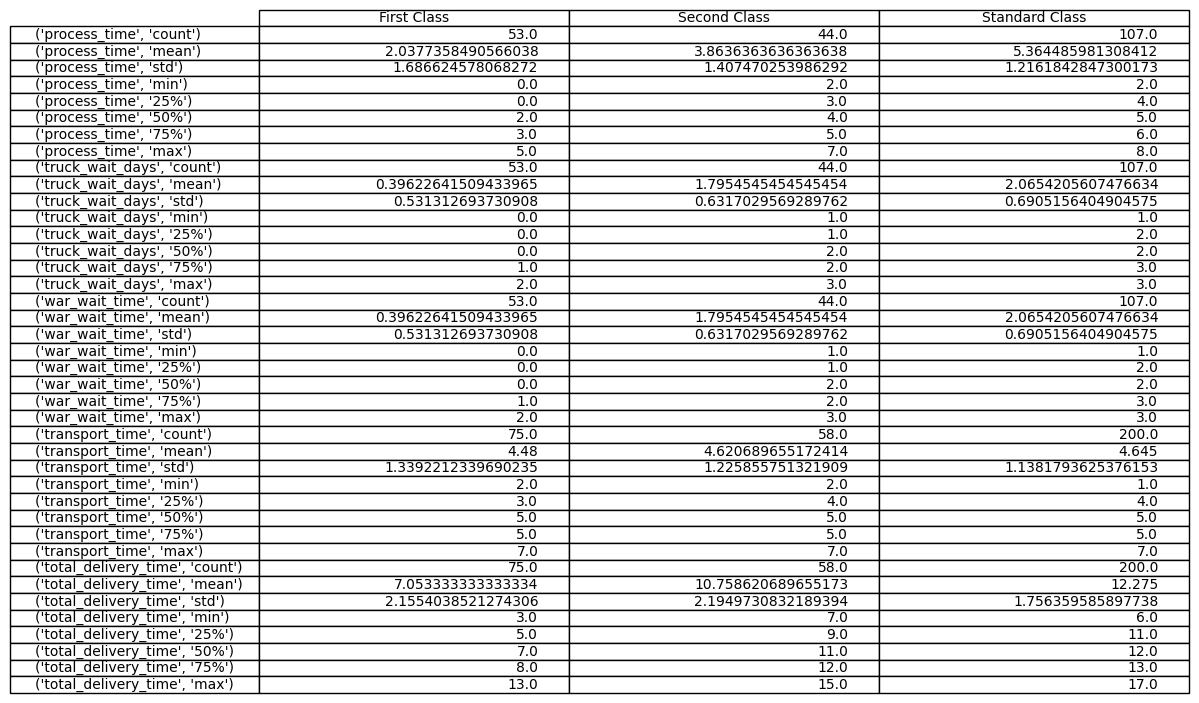

In [73]:
# by the shipment type:
table_1 = df_big_time.groupby("ship_mode")[[
    "process_time",
    "truck_wait_days",
    "war_wait_time",
    "transport_time",
    "total_delivery_time"
]].describe().T

# and save it as an image:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,6))
ax.axis('tight')
ax.axis('off')

# Draw table
ax.table(cellText=table_1.values,
         colLabels=table_1.columns,
         rowLabels=table_1.index,
         loc='center')

# Save image
plt.savefig("1_delivery_by_ship_mode_table.png", dpi=300, bbox_inches='tight')
plt.show()

Visualization of the relationship between shipment mode and the main KPIs:

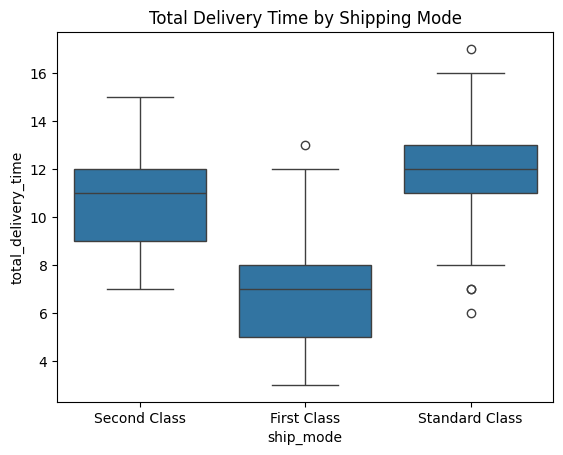

In [64]:
# if we want to see just one boxplot:
sns.boxplot(data=df_big_time,
            x="ship_mode",
            y="total_delivery_time")

plt.title("Total Delivery Time by Shipping Mode")
plt.show()

#plt.savefig("tot_deliv_time_by_shipping mode.png", dpi=300, bbox_inches='tight')


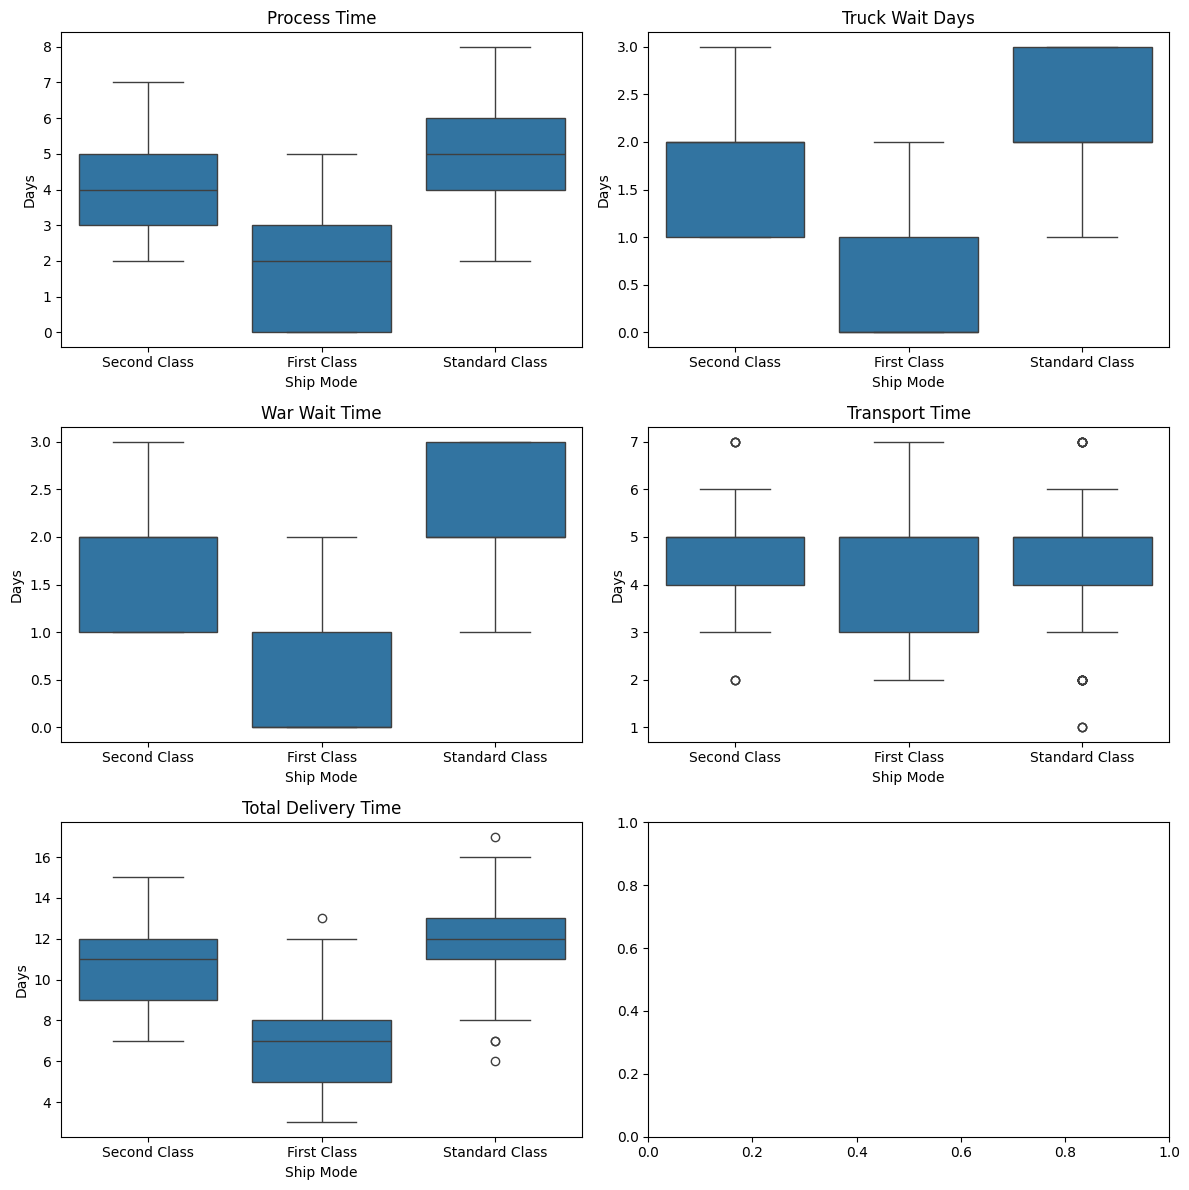

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt


# if we want all boxplots in one canvas:
metrics = [
    "process_time",
    "truck_wait_days",
    "war_wait_time",
    "transport_time",
    "total_delivery_time"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), metrics):
    sns.boxplot(data=df_big_time, x="ship_mode", y=metric, ax=ax)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Ship Mode")
    ax.set_ylabel("Days")

plt.tight_layout()
# plt.show()

plt.savefig("1_delivery_by_ship_mode.png", dpi=300, bbox_inches='tight')



### Origin Channels and Delivery Time
There are three ways to post the order in the company: ```['Email', 'Sales', 'Facebook']```.
We can check if it affects the delivery time.
Table 2 includes all the information about delivery time for clients grouped by the origin channels.


In [66]:
df_big_time['origin_channel'].unique()

<StringArray>
['Email', 'Sales', 'Facebook']
Length: 3, dtype: str

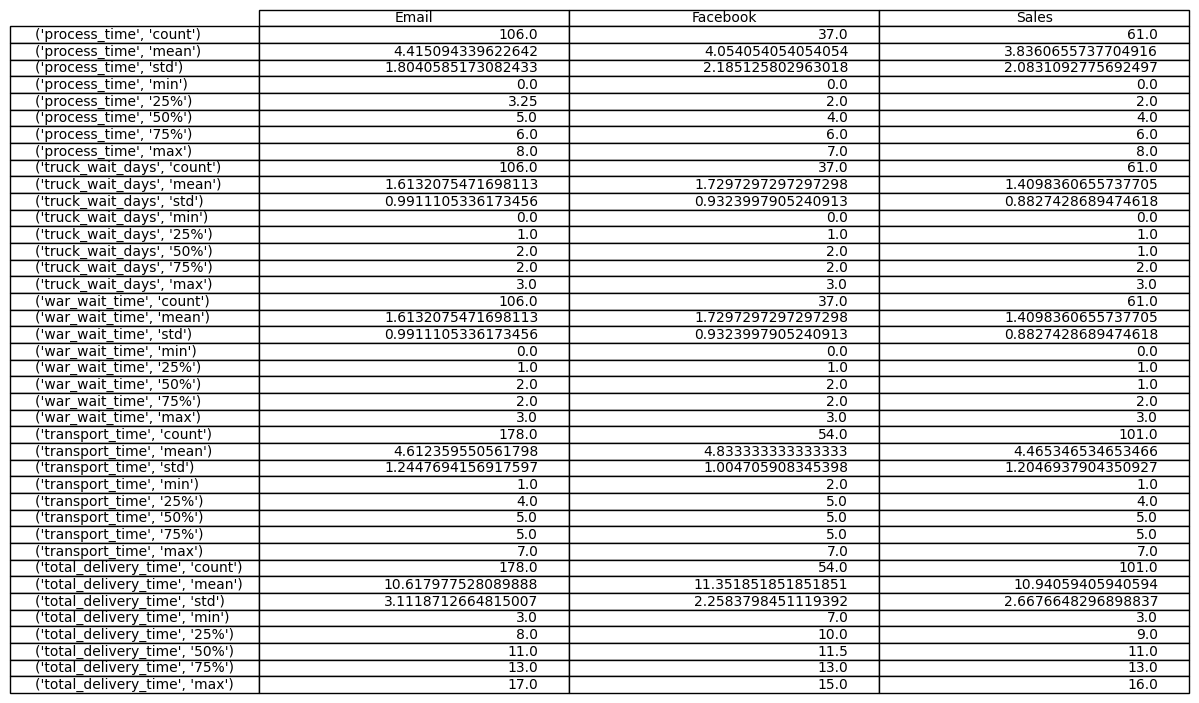

In [85]:
# 
table_2 = df_big_time.groupby("origin_channel")[[
    "process_time",
    "truck_wait_days",
    "war_wait_time",
    "transport_time",
    "total_delivery_time"
]].describe().T

# and save it as an image:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,6))
ax.axis('tight')
ax.axis('off')

# Draw table
ax.table(cellText=table_2.values,
         colLabels=table_2.columns,
         rowLabels=table_2.index,
         loc='center')

# Save image
plt.savefig("2_delivery_by_origin.png", dpi=300, bbox_inches='tight')
plt.show()

Now we also can visuzlize this relationships:

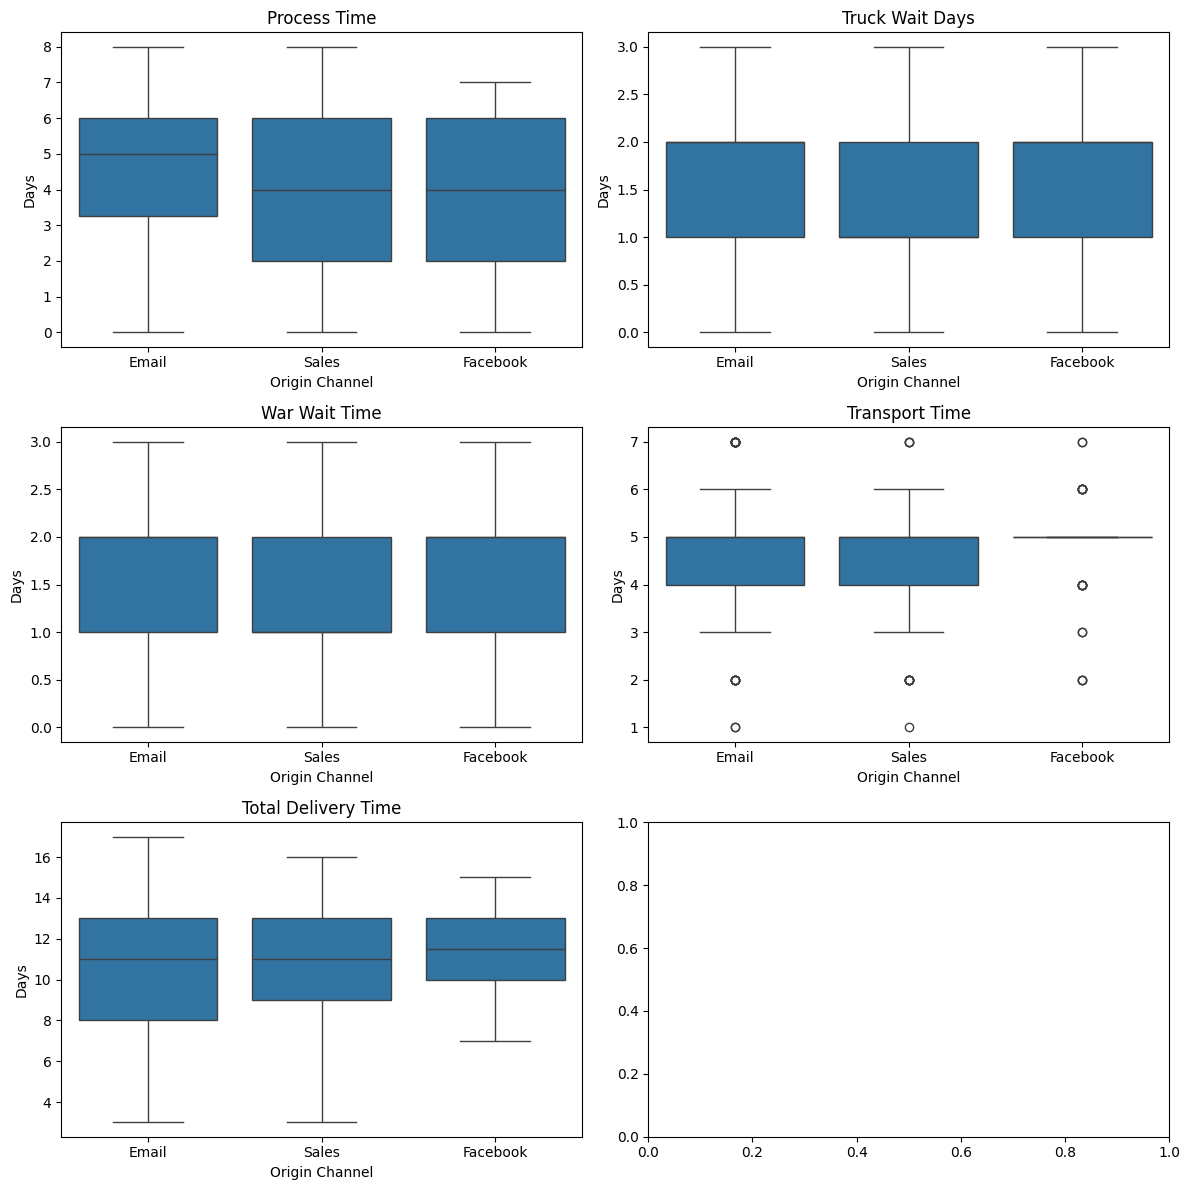

In [84]:
import seaborn as sns
import matplotlib.pyplot as plt


# if we want all boxplots in one canvas:
# metrics = [
#     "process_time",
#     "truck_wait_days",
#     "war_wait_time",
#     "transport_time",
#     "total_delivery_time"
# ]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), metrics):
    sns.boxplot(data=df_big_time, x="origin_channel", y=metric, ax=ax)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Origin Channel")
    ax.set_ylabel("Days")

plt.tight_layout()
# plt.show()

plt.savefig("2_delivery_all_by_origin.png", dpi=300, bbox_inches='tight')



### City, Region, State vs. Delivery time
We have geographical data about the clients who ordered from the company, and cah check if their location affects the total delivety time (and other metrics too).
In the dataframe there are three metrics for location:
```'city', 'state', 'region'```, so we will group by ```'region'``` and will skip ```'city'``` and ```'state'```because there are too many cities/states (531) for detailed analysis, we can do it in a different way later.


In [78]:
df_big_time.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'city', 'state',
       'postal_code', 'region', 'total_sales', 'total_profit', 'total_items',
       'ready_ship_weekday', 'pickup_weekday', 'truck_weekday',
       'arrival_weekday', 'process_time', 'war_wait_time', 'truck_wait_days',
       'transport_time', 'total_delivery_time'],
      dtype='str')

In [79]:
df_big_time['city'].nunique()

531

In [82]:
df_big_time['city'].nunique()

531

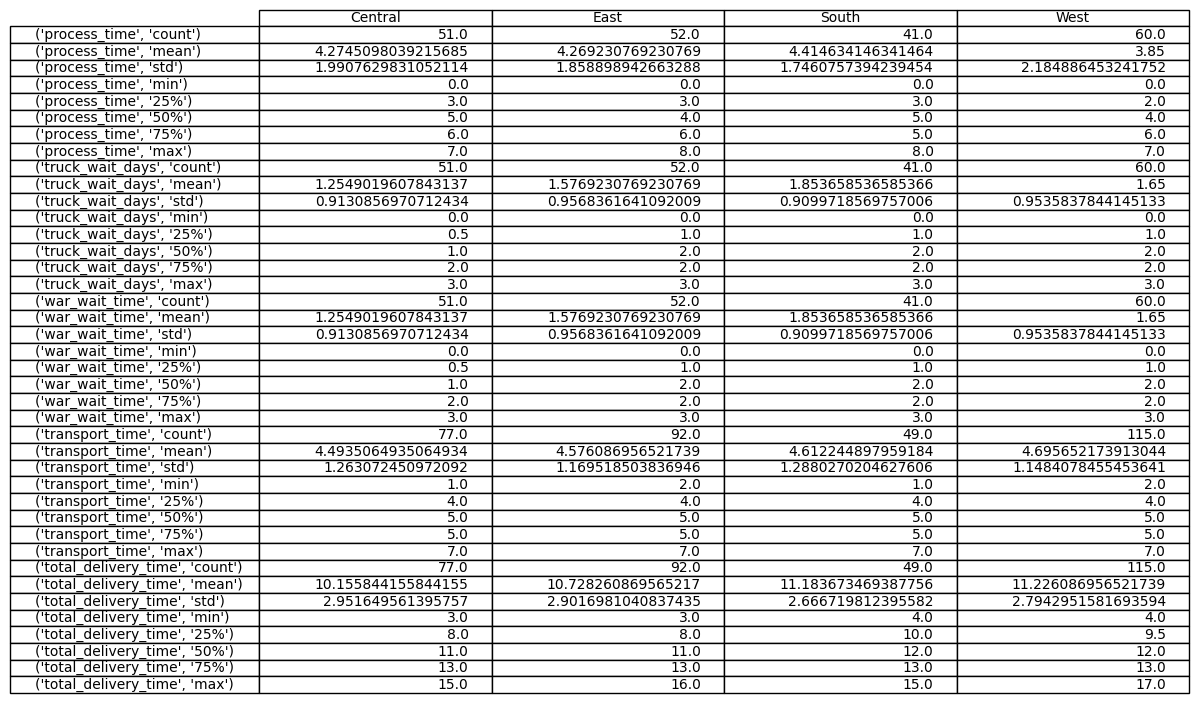

In [74]:
# 
table_3 = df_big_time.groupby("region")[[
    "process_time",
    "truck_wait_days",
    "war_wait_time",
    "transport_time",
    "total_delivery_time"
]].describe().T

# and save it as an image:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,6))
ax.axis('tight')
ax.axis('off')

# Draw table
ax.table(cellText=table_3.values,
         colLabels=table_3.columns,
         rowLabels=table_3.index,
         loc='center')

# Save image
plt.savefig("3_delivery_region_table.png", dpi=300, bbox_inches='tight')
plt.show()

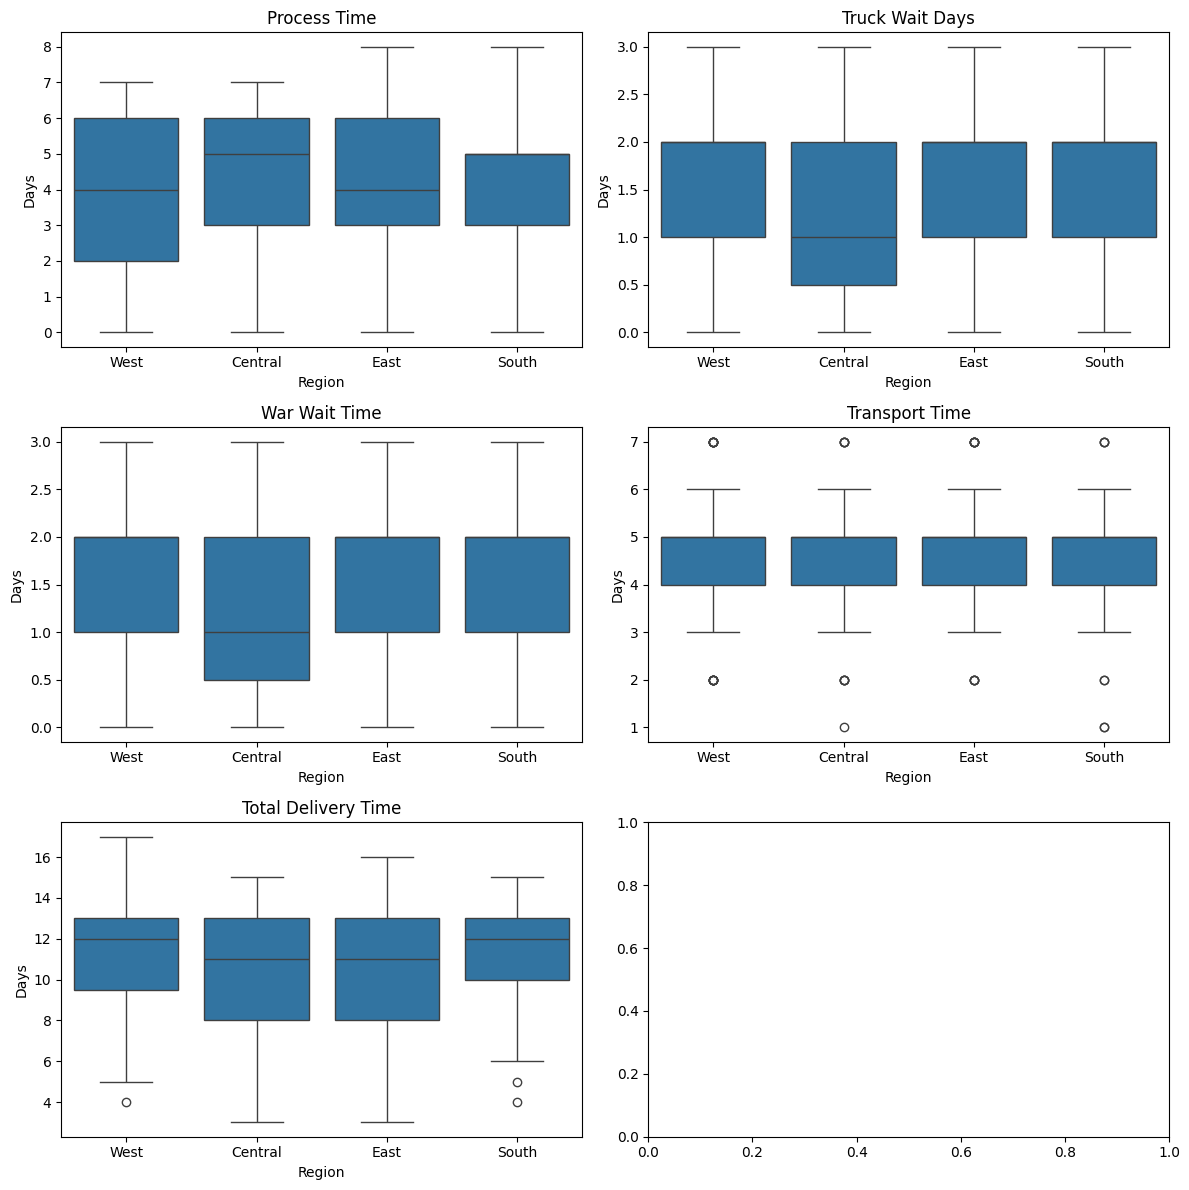

In [83]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), metrics):
    sns.boxplot(data=df_big_time, x="region", y=metric, ax=ax)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Region")
    ax.set_ylabel("Days")

plt.tight_layout()
# plt.show()

plt.savefig("3_delivery_all_by_region.png", dpi=300, bbox_inches='tight')

### Amount of Items
We have an idea that amount of items may affect processing time and warehouse waitign time, or -- in some cases -- the transportation time (e.g., not enough space in a truck). We have 40 different options for amount of items, so we will break our dataframe in four categories:
* less than 10
* between 10 and 20
* between 20 and 30
* more than 30 items

In [90]:
df_big_time['total_items'].nunique()

46

In [91]:
# making the groups by number of items:
bins = [0, 10, 20, 30, df_big_time["total_items"].max()]  # last group is 30+
labels = ["<10", "10-20", "20-30", "30+"]  # names for the groups

# Create a new column with the binned groups
df_big_time["items_group"] = pd.cut(df_big_time["total_items"],
                                    bins=bins,
                                    labels=labels,
                                    right=False)  # right=False means intervals like [0,10)

We can see that most of the orders (3667 orders) consist of small amount of items (less than 10), and just 60 orders were big (30+ items):

In [94]:
# check the groups:
df_big_time[["items_group"]].value_counts()

items_group
<10            3667
10-20          1074
20-30           207
30+              60
Name: count, dtype: int64

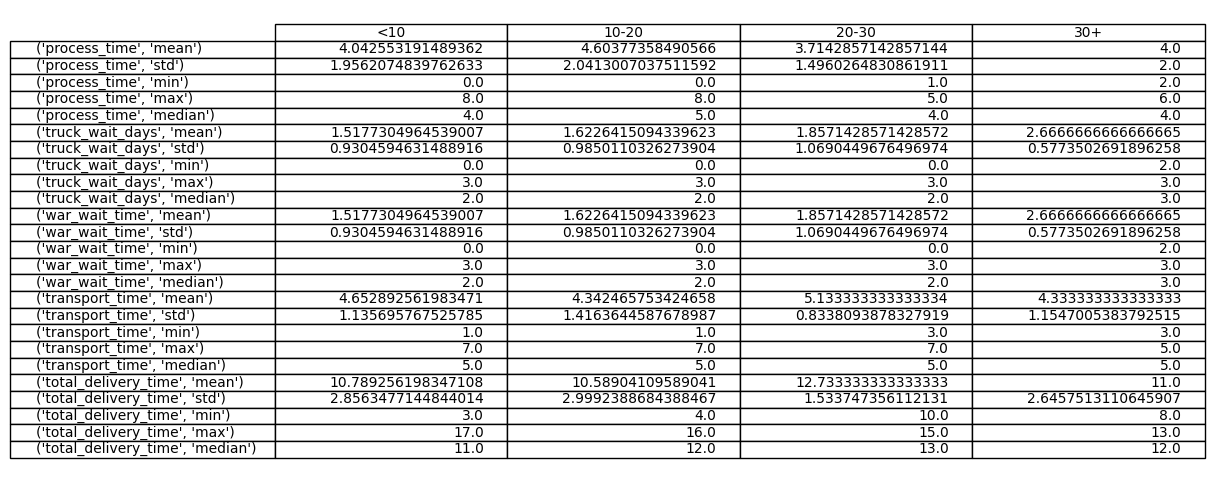

In [ ]:
# grouping + aggregation by the amount of items (categories)
table_4 = df_big_time.groupby("items_group")[[
    "process_time",
    "truck_wait_days",
    "war_wait_time",
    "transport_time",
    "total_delivery_time"
]].agg(["mean", "std", "min", "max", "median"]).T


# and save it as an image:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,6))
ax.axis('tight')
ax.axis('off')

# Draw table
ax.table(cellText=table_4.values,
         colLabels=table_4.columns,
         rowLabels=table_4.index,
         loc='center')

# Save image
plt.savefig("4_delivery_total_items.png", dpi=300, bbox_inches='tight')
plt.show()

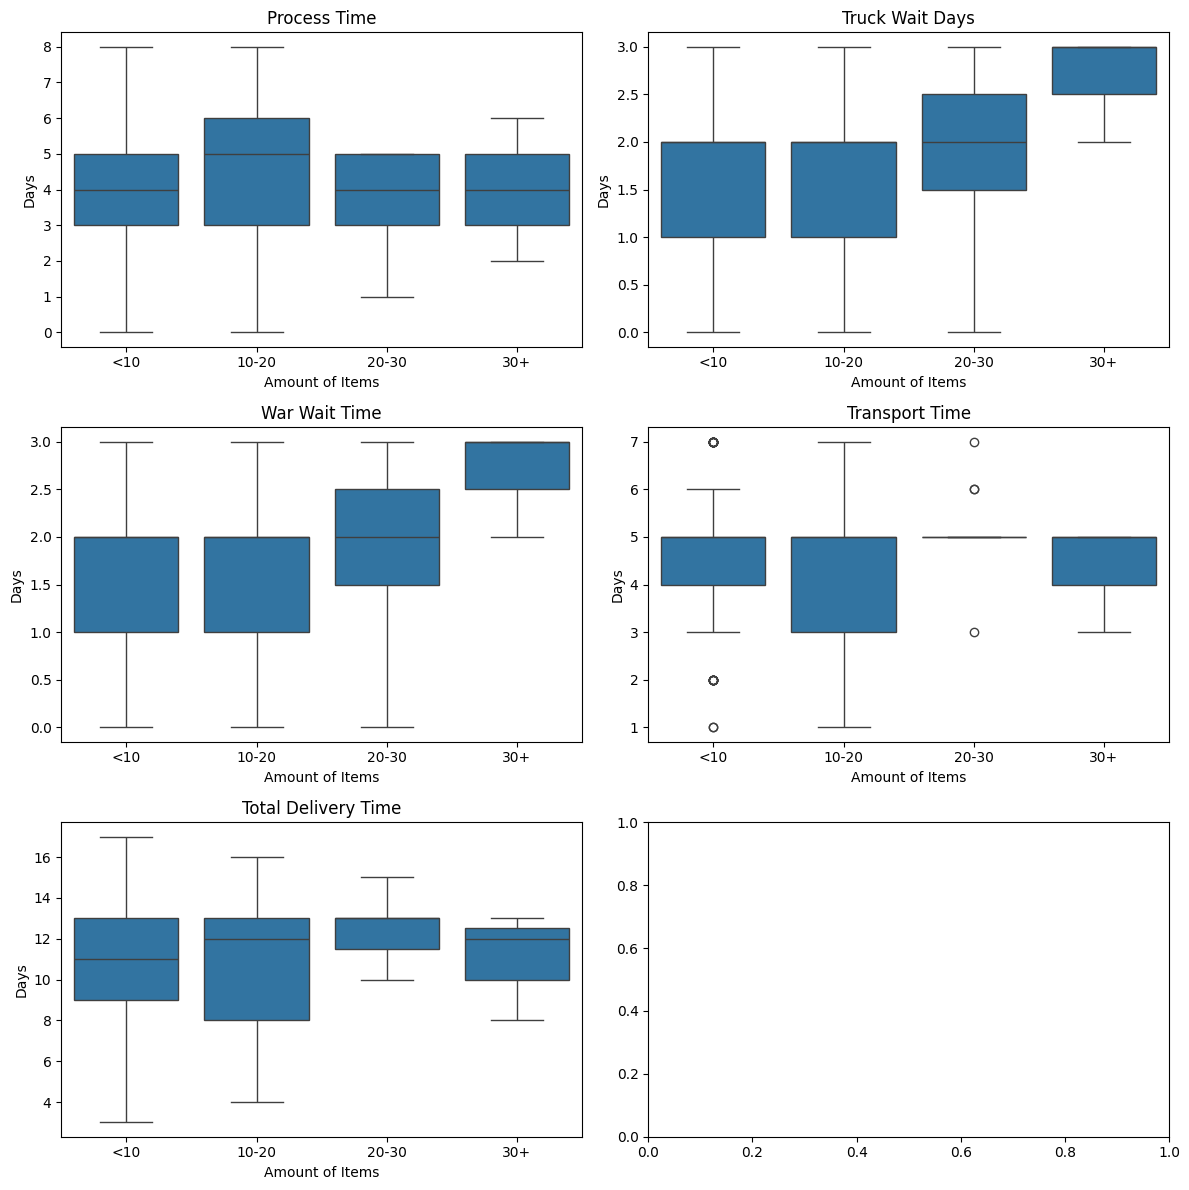

In [96]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), metrics):
    sns.boxplot(data=df_big_time, x="items_group", y=metric, ax=ax)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Amount of Items")
    ax.set_ylabel("Days")

plt.tight_layout()
# plt.show()

plt.savefig("4_delivery_all_total_items.png", dpi=300, bbox_inches='tight')

## Business Days Recalculation
We don't take into account -- so far -- that warehouse doesn't work on weekends, and when we calculate KPIs they are not ideal, because we need to include business days logic. It probably will correct our assumptions.
Including it into the analytical model also will allow us to compare the expectations (aka promisses from the warehouse and logistic company) to the real data.

In [106]:
df_big.columns

Index(['order_id', 'order_date', 'ship_mode', 'origin_channel', 'city',
       'state', 'postal_code', 'region', 'total_sales', 'total_profit',
       'total_items', 'ready_to_ship_date', 'pickup_date',
       'ready_ship_weekday', 'pickup_weekday', 'on_truck_scan_date',
       'truck_weekday', 'arrival_scan_date', 'arrival_weekday', 'process_time',
       'war_wait_time', 'truck_wait_days', 'transport_time',
       'total_delivery_time'],
      dtype='str')

In [109]:
df_big_biz = df_big.drop(columns=['city','postal_code', 'state',
    'origin_channel','total_sales', 'total_profit', 'truck_weekday',
    'ready_ship_weekday','pickup_weekday','arrival_weekday', 'process_time',
    'war_wait_time', 'truck_wait_days', 'transport_time', 'total_delivery_time'])

In [110]:
df_big_biz.head(2)

,order_id,order_date,ship_mode,region,total_items,ready_to_ship_date,pickup_date,on_truck_scan_date,arrival_scan_date
0,CA-2019-121755,2019-01-16,Second Class,West,5,NaT,NaT,2019-01-23,NaT
1,CA-2019-118255,2019-03-11,First Class,Central,4,NaT,NaT,2019-03-13,NaT


In [114]:
df_big_biz.dtypes

order_id                         str
order_date            datetime64[us]
ship_mode                        str
region                           str
total_items                    int64
ready_to_ship_date    datetime64[us]
pickup_date           datetime64[us]
on_truck_scan_date    datetime64[us]
arrival_scan_date     datetime64[us]
dtype: object

In [104]:
import numpy as np

In [ ]:
# now we need to re-calcualte our metrics 
# processing_time
mask = df_big_biz["order_date"].notna() & df_big_biz["ready_to_ship_date"].notna()

df_big_biz.loc[mask, "process_days_biz"] = np.busday_count(
    df_big_biz.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_big_biz.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]")
)

In [116]:
df_big_biz['process_days_biz'].describe()

count    204.000000
mean       2.769608
std        1.417991
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: process_days_biz, dtype: float64

In [118]:
# truck waiting days
mask = df_big_biz["pickup_date"].notna() & df_big_biz["ready_to_ship_date"].notna()

df_big_biz.loc[mask, "truck_wait_days_biz"] = np.busday_count(
    df_big_biz.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_big_biz.loc[mask, "pickup_date"].values.astype("datetime64[D]")
)

In [119]:
df_big_biz['truck_wait_days_biz'].describe()

count    204.000000
mean       1.357843
std        0.821141
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        3.000000
Name: truck_wait_days_biz, dtype: float64

In [120]:
df_big_biz.columns

Index(['order_id', 'order_date', 'ship_mode', 'region', 'total_items',
       'ready_to_ship_date', 'pickup_date', 'on_truck_scan_date',
       'arrival_scan_date', 'process_days_biz', 'truck_wait_days_biz'],
      dtype='str')

In [121]:
# warehouse waiting days
mask = df_big_biz["on_truck_scan_date"].notna() & df_big_biz["ready_to_ship_date"].notna()

df_big_biz.loc[mask, "war_wait_days_biz"] = np.busday_count(
    df_big_biz.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_big_biz.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]")
)

In [122]:
df_big_biz['war_wait_days_biz'].describe()

count    204.000000
mean       1.357843
std        0.821141
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        3.000000
Name: war_wait_days_biz, dtype: float64

In [123]:
# transport days
mask = df_big_biz["arrival_scan_date"].notna() & df_big_biz["on_truck_scan_date"].notna()

df_big_biz.loc[mask, "transp_days_biz"] = np.busday_count(
    df_big_biz.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]"),
    df_big_biz.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

In [124]:
df_big_biz['transp_days_biz'].describe()

count    333.000000
mean       2.921922
std        0.956855
min        1.000000
25%        3.000000
50%        3.000000
75%        3.000000
max        5.000000
Name: transp_days_biz, dtype: float64

In [125]:
# total delivery time:

mask = df_big_biz["order_date"].notna() & df_big_biz["arrival_scan_date"].notna()

df_big_biz.loc[mask, "total_delivery_days_biz"] = np.busday_count(
    df_big_biz.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_big_biz.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_big_biz['total_delivery_days_biz'].describe()


count    333.000000
mean       7.399399
std        2.050477
min        1.000000
25%        6.000000
50%        8.000000
75%        9.000000
max       12.000000
Name: total_delivery_days_biz, dtype: float64

In [126]:
df_big_biz.columns

Index(['order_id', 'order_date', 'ship_mode', 'region', 'total_items',
       'ready_to_ship_date', 'pickup_date', 'on_truck_scan_date',
       'arrival_scan_date', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz'],
      dtype='str')

In [133]:
table_5 = df_big_biz[['process_days_biz','truck_wait_days_biz','war_wait_days_biz','transp_days_biz','total_delivery_days_biz']].describe().T

In [134]:
table_5

,count,mean,std,min,25%,50%,75%,max
process_days_biz,204.0,2.769608,1.417991,0.0,2.0,3.0,4.0,5.0
truck_wait_days_biz,204.0,1.357843,0.821141,0.0,1.0,1.0,2.0,3.0
war_wait_days_biz,204.0,1.357843,0.821141,0.0,1.0,1.0,2.0,3.0
transp_days_biz,333.0,2.921922,0.956855,1.0,3.0,3.0,3.0,5.0
total_delivery_days_biz,333.0,7.399399,2.050477,1.0,6.0,8.0,9.0,12.0


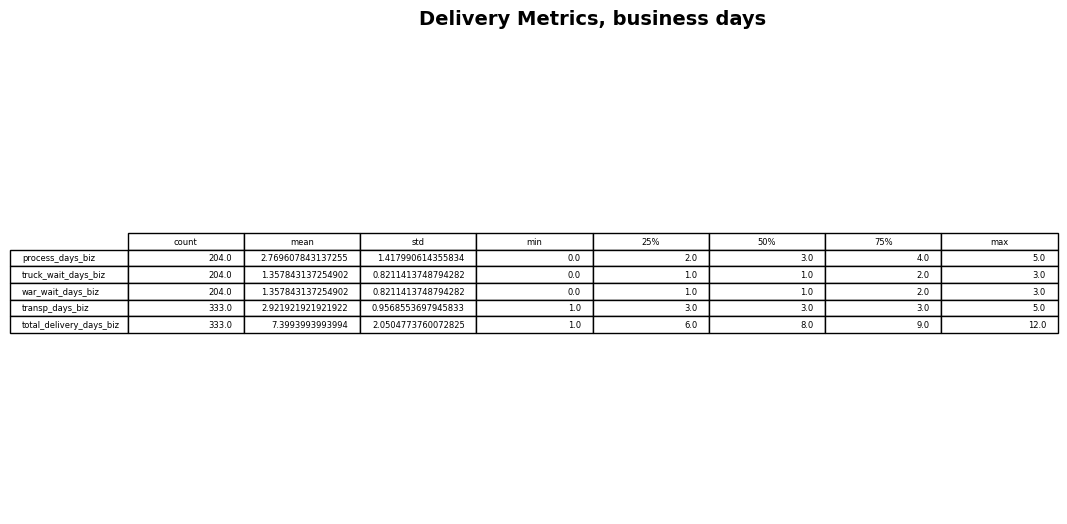

In [142]:
fig, ax = plt.subplots(figsize=(12,6))
ax.axis('tight')
ax.axis('off')

# draw table
ax.table(cellText=table_5.values,
         colLabels=table_5.columns,
         rowLabels=table_5.index,
         loc='center')

# title:
ax.set_title("Delivery Metrics, business days", fontsize=14, fontweight='bold', pad=20)

# save image
plt.savefig("5_biz_days_stat.png", dpi=300, bbox_inches='tight')
plt.show()

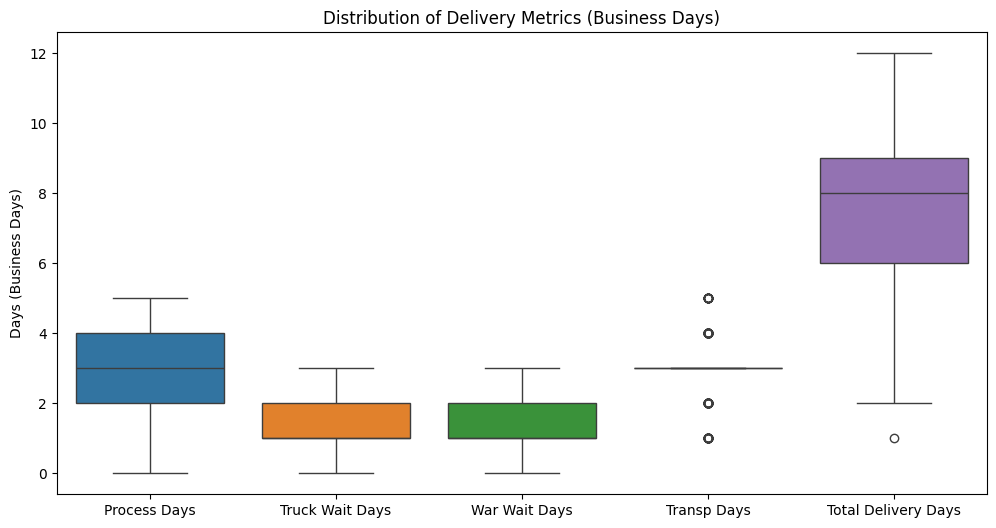

In [140]:
columns = [
    "process_days_biz",
    "truck_wait_days_biz",
    "war_wait_days_biz",
    "transp_days_biz",
    "total_delivery_days_biz"
]

# Plot
plt.figure(figsize=(12,6))
sns.boxplot(data=df_big_biz[columns])

# Optional: nicer x-axis labels
plt.xticks(ticks=range(len(columns)),
           labels=[c.replace("_biz","").replace("_"," ").title() for c in columns])

plt.ylabel("Days (Business Days)")
plt.title("Distribution of Delivery Metrics (Business Days)")
# plt.show()

plt.savefig("5_biz_days_boxplot.png", dpi=300, bbox_inches='tight')